An educational institution wants to identify students who are at risk of failing their examinations.

Build a Machine Learning classification model using Random Forest Classifier that predicts whether a student will Pass or Fail based on their academic performance, attendance, study habits and lifestyle.

The institution can use these predictions to identify students who may need additional academic support.

In [200]:
import numpy as np 
import pandas as pd


In [201]:
df=pd.read_csv('random_forest_student_performance.csv')
cdf=df

In [202]:
cdf.head()

,Study_Hours_Per_Day,Attendance_Percentage,Assignment_Score,Previous_Exam_Score,Sleep_Hours,Extracurricular_Hours_Per_Week,Result
0,4.3,60.8,64.9,81.5,7.0,2.2,Pass
1,2.2,71.7,87.7,100.0,7.6,3.4,Pass
2,4.9,83.5,76.5,41.4,7.0,0.7,Pass
3,5.2,76.7,60.8,89.8,8.1,1.6,Pass
4,0.9,69.5,58.1,66.2,6.5,0.4,Fail


In [203]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Study_Hours_Per_Day             1200 non-null   float64
 1   Attendance_Percentage           1200 non-null   float64
 2   Assignment_Score                1200 non-null   float64
 3   Previous_Exam_Score             1200 non-null   float64
 4   Sleep_Hours                     1200 non-null   float64
 5   Extracurricular_Hours_Per_Week  1200 non-null   float64
 6   Result                          1200 non-null   object 
dtypes: float64(6), object(1)
memory usage: 65.8+ KB


In [204]:
cdf.isna().sum()

Study_Hours_Per_Day               0
Attendance_Percentage             0
Assignment_Score                  0
Previous_Exam_Score               0
Sleep_Hours                       0
Extracurricular_Hours_Per_Week    0
Result                            0
dtype: int64

In [205]:
cdf.duplicated().sum()

np.int64(0)

<Axes: xlabel='Study_Hours_Per_Day', ylabel='count'>

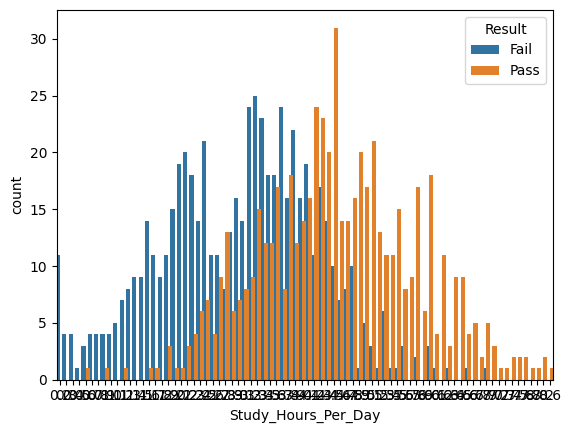

In [206]:
import seaborn as sns

sns.countplot(data=cdf,x=cdf['Study_Hours_Per_Day'],hue=cdf['Result'],gap=2,width=1.3,)

In [207]:
X=cdf.drop(['Result'],axis=1)
Y=cdf.Result

***BY SINGLE DECISON TREE***

In [208]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
x_train,x_test,y_train,y_test=train_test_split(X,Y,random_state=42,stratify=Y,test_size=0.2)
decisontreemodel=DecisionTreeClassifier()
decisontreemodel.fit(x_train,y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [209]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
y_pred=decisontreemodel.predict(x_test)
print("Base model Acuracy :",accuracy_score(y_test,y_pred))
print("Base Model classifiction Report :")
print(classification_report(y_test,y_pred))
print("Base model Confusion Matrix :")
print(confusion_matrix(y_test,y_pred))

Base model Acuracy : 0.7291666666666666
Base Model classifiction Report :
              precision    recall  f1-score   support

        Fail       0.73      0.75      0.74       123
        Pass       0.73      0.71      0.72       117

    accuracy                           0.73       240
   macro avg       0.73      0.73      0.73       240
weighted avg       0.73      0.73      0.73       240

Base model Confusion Matrix :
[[92 31]
 [34 83]]


In [210]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
x_train,x_test,y_train,y_test=train_test_split(X,Y,random_state=42,stratify=Y,test_size=0.2)

basemodel=RandomForestClassifier()
basemodel.fit(x_train,y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [211]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
y_pred=basemodel.predict(x_test)
print("Base model Acuracy :",accuracy_score(y_test,y_pred))
print("Base Model classifiction Report :")
print(classification_report(y_test,y_pred))
print("Base model Confusion Matrix :")
print(confusion_matrix(y_test,y_pred))


Base model Acuracy : 0.7875
Base Model classifiction Report :
              precision    recall  f1-score   support

        Fail       0.78      0.82      0.80       123
        Pass       0.80      0.75      0.78       117

    accuracy                           0.79       240
   macro avg       0.79      0.79      0.79       240
weighted avg       0.79      0.79      0.79       240

Base model Confusion Matrix :
[[101  22]
 [ 29  88]]


In [212]:
x_test

,Study_Hours_Per_Day,Attendance_Percentage,Assignment_Score,Previous_Exam_Score,Sleep_Hours,Extracurricular_Hours_Per_Week
1162,3.4,73.4,51.9,70.1,8.8,0.6
642,6.9,89.4,57.8,47.2,7.8,1.5
61,3.3,79.3,51.0,71.8,7.7,3.5
1039,4.8,74.0,100.0,54.7,5.4,0.9
573,2.5,100.0,62.7,52.3,6.3,2.2
...,...,...,...,...,...,...
1123,3.4,78.2,46.6,58.9,5.7,4.0
47,4.1,54.5,64.7,58.3,7.7,2.6
622,4.2,93.9,78.4,100.0,6.8,1.0
1185,1.7,70.0,100.0,38.5,7.6,3.2


In [213]:
newdata=pd.DataFrame({
    "Study_Hours_Per_Day":[3.4],
    "Attendance_Percentage":[73.4],
    "Assignment_Score":[51.9],
    "Previous_Exam_Score":[70.1],
    "Sleep_Hours":[8.8],
    "Extracurricular_Hours_Per_Week":[0.6],
})


In [214]:
print("PREDICTION ON TRAINING DATA")
y_test.head(1)

PREDICTION ON TRAINING DATA


1162    Fail
Name: Result, dtype: object

In [215]:
print("MODEL PREDICTION FOR TRAINING DATA")
print(basemodel.predict(newdata))

MODEL PREDICTION FOR TRAINING DATA
['Fail']


In [216]:
newdata=pd.DataFrame({
    "Study_Hours_Per_Day":[7.5],
    "Attendance_Percentage":[92],
    "Assignment_Score":[88],
    "Previous_Exam_Score":[85],
    "Sleep_Hours":[7.5],
    "Extracurricular_Hours_Per_Week":[2],
})

print("MODEL PREDCITON ON UNSEEN DATA")
print(basemodel.predict(newdata))

MODEL PREDCITON ON UNSEEN DATA
['Pass']


***USIING GRID SEARCH CV***

In [217]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

def Random_Forest_model(max_features):
    return Pipeline([
        ("random",RandomForestClassifier(max_features=max_features))
    ])

In [218]:
param_grid={
    "random__max_features":list(range(4))
}

grid=GridSearchCV(
    estimator=Random_Forest_model(max_features=1),
    param_grid=param_grid,
    cv=4,
    scoring='accuracy',
)

grid.fit(x_train,y_train)

c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
4 fits failed out of a total of 16.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\Pawan\AppData\

,estimator,Pipeline(step...features=1))])
,param_grid,"{'random__max_features': [0, 1, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [219]:


print("Base model Acuracy :",accuracy_score(y_test,y_pred))
print("Base Model classifiction Report :")
print(classification_report(y_test,y_pred))
print("Base model Confusion Matrix :")
print(confusion_matrix(y_test,y_pred))

print("-"*70)

bestmodel=grid.best_estimator_
print("Best Model PARAM :",grid.best_params_)
print('BEST MODEL CV MEAN ACCURACY',grid.best_score_)
print("Best Model classifiction Report :")
print(classification_report(y_test,y_pred))
print("Best model Confusion Matrix :")
print(confusion_matrix(y_test,y_pred))


Base model Acuracy : 0.7875
Base Model classifiction Report :
              precision    recall  f1-score   support

        Fail       0.78      0.82      0.80       123
        Pass       0.80      0.75      0.78       117

    accuracy                           0.79       240
   macro avg       0.79      0.79      0.79       240
weighted avg       0.79      0.79      0.79       240

Base model Confusion Matrix :
[[101  22]
 [ 29  88]]
----------------------------------------------------------------------
Best Model PARAM : {'random__max_features': 2}
BEST MODEL CV MEAN ACCURACY 0.8114583333333334
Best Model classifiction Report :
              precision    recall  f1-score   support

        Fail       0.78      0.82      0.80       123
        Pass       0.80      0.75      0.78       117

    accuracy                           0.79       240
   macro avg       0.79      0.79      0.79       240
weighted avg       0.79      0.79      0.79       240

Best model Confusion Matrix :
[[